# In-class Competition Tutorial
This NOTEBOOK will provide an introduction to the process of creating forecast results and the basic methodology.

First, let's review the task we will be performing (see README.ipynb for details).

**Objective**: To predict the probability of default based on customer data.

**Evaluation metric**: ROC-AUC (Area Under the Receiver Operating Characteristic Curve)

## Contents
- [1.Setup](#scrollTo=a5KcDAE8CnmB)
- [2.Loading the Data](#scrollTo=tp0cW0CD11Hi&line=1&uniqifier=1)
- [3.Visualizing and Understanding the Data](#scrollTo=3NuP1zcmCnmF&line=1&uniqifier=1)
- [4.Preprocessing and Feature Creation](#scrollTo=rsPYkguwCnmO&line=1&uniqifier=1)
- [5.Building the Machine Learning Model](#scrollTo=FoKdK60PCnmP&line=1&uniqifier=1)
- [6.Creating prediction results](#scrollTo=tn_kdvWYCnmQ&line=2&uniqifier=1)

## 1.Setup

### 1.1 Import Libraries
Let's load basic libraries.
Other required libraries will be loaded when we explain them.
- numpy: Library for efficient numerical computation
- pandas: Library useful for data analysis
- matplotlib: Graph drawing library
- seaborn: Graph drawing library as well

In [43]:
# Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

### 1.2 Local Directory Setup
We load the data directly from the local `input/` folder in this workspace.


In [44]:
# Local execution (no Google Drive needed)
import os
from pathlib import Path

current_dir = Path.cwd()
print('Working directory:', current_dir)


Working directory: c:\Users\Hareen Liyanage\Desktop\GCI_World_Competition


Check the input directory location.


In [45]:
# Verify input folder
input_dir = current_dir / 'input'
print('Input directory:', input_dir)
print('Input directory exists:', input_dir.exists())


Input directory: c:\Users\Hareen Liyanage\Desktop\GCI_World_Competition\input
Input directory exists: True


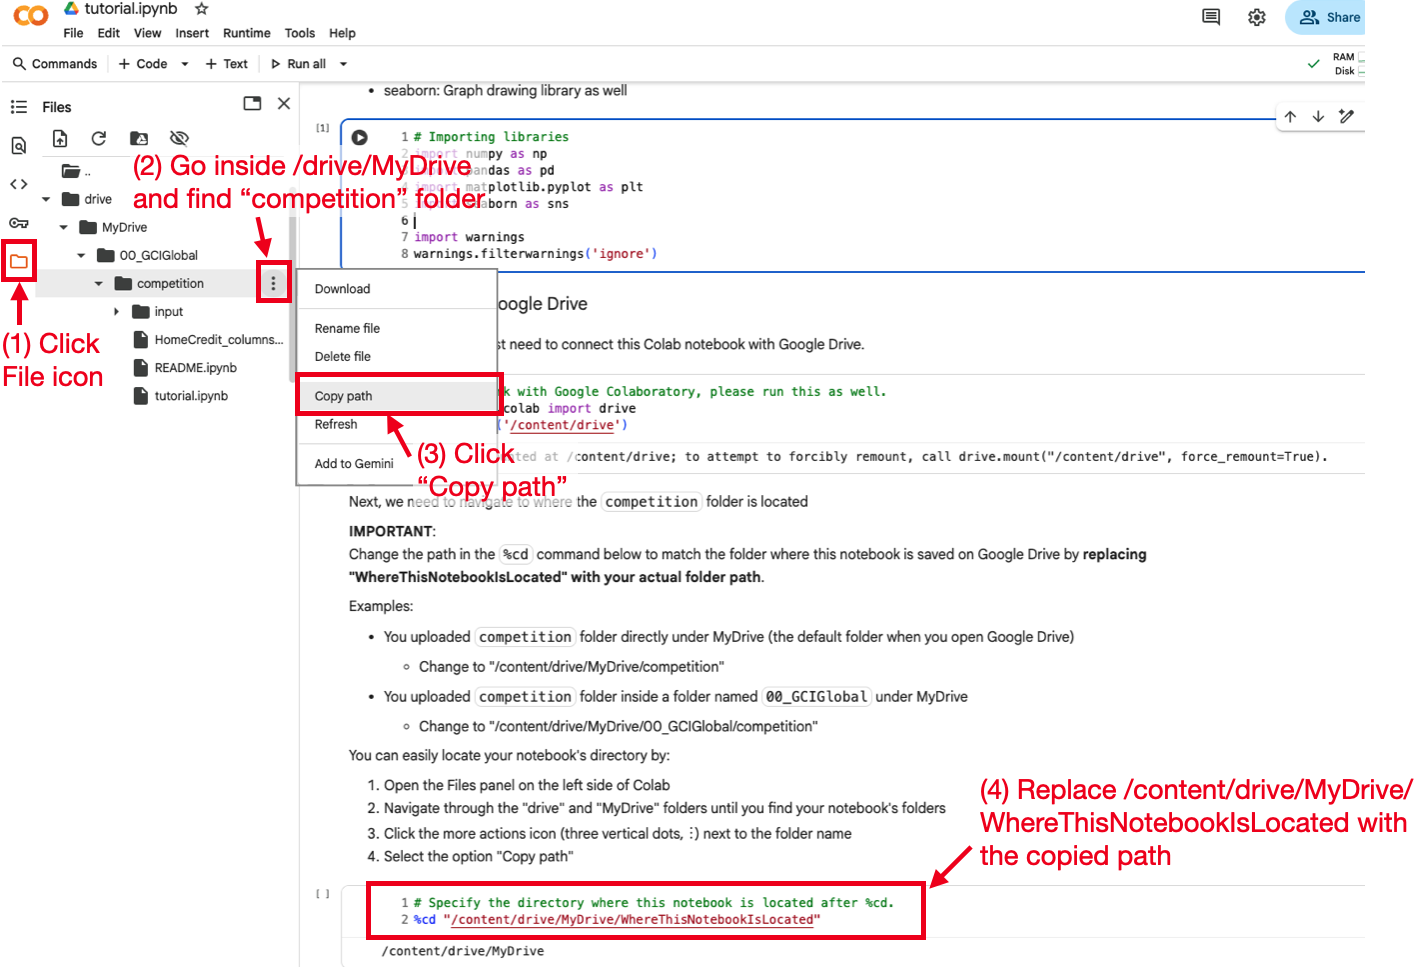

Run the cell below to check if the path is correctly set.

In [46]:
import os
from pathlib import Path

current_dir = Path.cwd()

# Local file paths
train_file = current_dir / 'input' / 'train.csv'
test_file = current_dir / 'input' / 'test.csv'
sample_sub_file = current_dir / 'input' / 'sample_submission.csv'

# Check if files exist
if train_file.exists() and test_file.exists() and sample_sub_file.exists():
    print('All files exist and local path is correctly set.')
    print('Train path:', train_file)
    print('Test path :', test_file)
else:
    print(f'Error: Could not find files in {current_dir / "input"}')


All files exist and local path is correctly set.
Train path: c:\Users\Hareen Liyanage\Desktop\GCI_World_Competition\input\train.csv
Test path : c:\Users\Hareen Liyanage\Desktop\GCI_World_Competition\input\test.csv


## 2.Loading the Data

### 2.1 Data Overview
Run the cell to load the dataset as `pd.DataFrame`.

**IMPORTANT:**<br>
**When you make modifications to preprocessing or model training, always make sure to run all cells from this cell.**

In [47]:
train = pd.read_csv(train_file)
test = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)
print('Loaded train shape:', train.shape)
print('Loaded test shape :', test.shape)


Loaded train shape: (171202, 34)
Loaded test shape : (61500, 33)


In [48]:
# Data successfully loaded
print('Dataset ready for analysis.')


Dataset ready for analysis.


Before conducting a full-scale analysis, we will first review a brief overview of the data.

In [49]:
# Check train data
print(f"train shape: {train.shape}")
train.head(3)

train shape: (171202, 34)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0


In [50]:
# Check test data
print(f"test shape: {test.shape}")
test.head(3)

test shape: (61500, 33)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,171202,Cash loans,F,1,144000.0,961146.0,28233.0,688500.0,Working,Higher education,...,2,Kindergarten,NaN,0.720416,NaN,-1.0,NaN,NaN,NaN,NaN
1,171203,Cash loans,F,0,103500.0,296280.0,16069.5,225000.0,Working,Secondary / secondary special,...,2,School,NaN,0.287306,NaN,-212.0,NaN,NaN,NaN,NaN
2,171204,Cash loans,F,1,180000.0,183694.5,11236.5,139500.0,Commercial associate,Secondary / secondary special,...,3,Trade: type 7,NaN,0.352456,0.389339,-428.0,0.0,1.0,1.0,1.0


Excluding the `TARGET` column in train data and the `SK_ID_CURR` which represents ID number, you can see that there are 32 types of features.

### 2.2 Selecting Features

It is often difficult to perform data analysis and preprocessing on all features from the beginning. Instead, an easier way to get started is to start with a small number of features and then add features one by one.

This notebook will focus on 5 features. For the remaining 25 types of features, please refer to the lecture materials, the methods introduced in this notebook, etc., and perform the analysis on your own.

Feel free to also ask questions in lectures, office hours, or in the Slack community!

In [51]:
# Use ALL features (we will handle categoricals below)
import os
from pathlib import Path
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

current_dir = Path.cwd()
train_file = current_dir / 'input' / 'train.csv'
test_file  = current_dir / 'input' / 'test.csv'
sample_sub_file = current_dir / 'input' / 'sample_submission.csv'

train_full = pd.read_csv(train_file)
test_full  = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)

target = train_full['TARGET'].values

# Drop ID and target from feature sets
drop_cols = ['SK_ID_CURR', 'TARGET']
train_feats = train_full.drop(columns=drop_cols)
test_feats  = test_full.drop(columns=['SK_ID_CURR'])

print('Train features shape:', train_feats.shape)
print('Test  features shape:', test_feats.shape)


Train features shape: (171202, 32)
Test  features shape: (61500, 32)


Let's check the data once again.

In [52]:
# Check train data
print(f"train shape: {train.shape}")
train.head(3)

train shape: (171202, 34)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0


In [53]:
# Check test data
print(f"test shape: {test.shape}")
test.head(3)

test shape: (61500, 33)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,171202,Cash loans,F,1,144000.0,961146.0,28233.0,688500.0,Working,Higher education,...,2,Kindergarten,NaN,0.720416,NaN,-1.0,NaN,NaN,NaN,NaN
1,171203,Cash loans,F,0,103500.0,296280.0,16069.5,225000.0,Working,Secondary / secondary special,...,2,School,NaN,0.287306,NaN,-212.0,NaN,NaN,NaN,NaN
2,171204,Cash loans,F,1,180000.0,183694.5,11236.5,139500.0,Commercial associate,Secondary / secondary special,...,3,Trade: type 7,NaN,0.352456,0.389339,-428.0,0.0,1.0,1.0,1.0


### **[Next Steps]**
> + Try adding more features, starting with the ones that you think are more relevant for predicting default probability. Check `HomeCredit_columns_description.xlsx` to understand what each column represents.
> + When you add new features, always restart from [Section 2.1](#scrollTo=2TTHzi1c3a5E&line=5&uniqifier=1) by reloading the dataset.

## 3.Visualizing and Understanding the Data

The first thing we need to do before building the machine learning model is to **understand the data**. We do this by visualizing and analyzing, to deepen our understanding of data distribution, missing values, outliers, correlations, and etc. The results of the analysis obtained at this stage will be useful for preprocessing, feature creation, and selection of machine learning models, which are all important to building models with better prediction ability.

### 3.1 Checking missing values
In this section, we check for missing values.
This is important as **most machine learning models cannot be trained on data with missing values**. If there are missing values, they need to be filled with some value.

In [54]:
# Check missing values of train data (top 20 columns)
miss = train_feats.isnull().sum()
miss = miss[miss > 0].sort_values(ascending=False)
print("Columns with missing values:", len(miss))
miss.head(20)


Columns with missing values: 9


EXT_SOURCE_1                  118928
OWN_CAR_AGE                   112992
EXT_SOURCE_3                   54586
AMT_REQ_CREDIT_BUREAU_MON      23116
AMT_REQ_CREDIT_BUREAU_HOUR     23116
AMT_REQ_CREDIT_BUREAU_QRT      23116
AMT_REQ_CREDIT_BUREAU_YEAR     23116
EXT_SOURCE_2                     369
CNT_FAM_MEMBERS                    2
dtype: int64

In [55]:
# Check missing values of test data (top 20)
miss_test = test_feats.isnull().sum()
miss_test = miss_test[miss_test > 0].sort_values(ascending=False)
print("Test columns with missing values:", len(miss_test))
miss_test.head(20)


Test columns with missing values: 8


EXT_SOURCE_1                  42912
OWN_CAR_AGE                   40909
EXT_SOURCE_3                  19690
AMT_REQ_CREDIT_BUREAU_HOUR     8513
AMT_REQ_CREDIT_BUREAU_QRT      8513
AMT_REQ_CREDIT_BUREAU_MON      8513
AMT_REQ_CREDIT_BUREAU_YEAR     8513
EXT_SOURCE_2                    130
dtype: int64

We found that there are missing values in `EXT_SOURCE_2` and `OWN_CAR_AGE`. We will deal with these missing values later. Of course, there is a possibility that there are missing values for other features that we are not covering here, so please check them by yourself.

**Findings**:<br>
* Need to deal with missing values in `EXT_SOURCE_2` and `OWN_CAR_AGE`

### 3.2 Visualization and analysis of each feature
In this section, we visualize each feature and analyze to see what kind of characteristics it has.

#### TARGET column

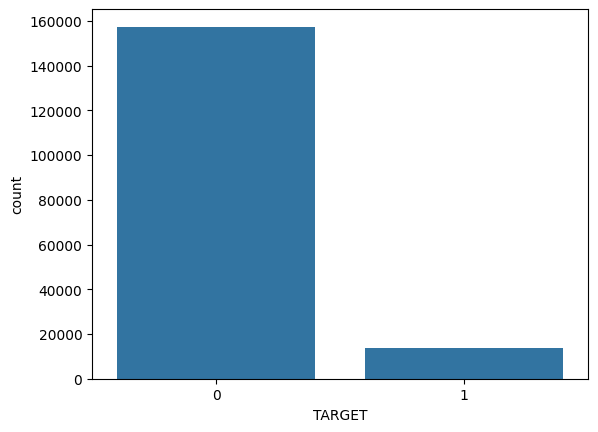

In [56]:
# The distribution of the target (default or not)
sns.countplot(data=train, x="TARGET")
plt.show()

We can see that the **distribution of the objective variable is highly skewed**. Data in which the distribution of the objective variable is highly skewed in this way is called **unbalanced data**.

When dealing with unbalanced data, we need to be particularly careful in selecting evaluation metrics. For example, if you choose accuracy, you will find that simply predicting all zeros will result in a high accuracy. **Choosing such an inappropriate metric can cause the machine learning model to fail to predict well on new data**.

Another approach to dealing with unbalanced data is to try to balance the distribution of the target variable. The method of reducing the data of the larger target variable is called undersampling, while the method of increasing the data of the smaller objective variable is called oversampling.

**Findings**:<br>
* (May) need to think about methods to mitigate the skewedness of the target variable

#### NAME_CONTRACT_TYPE column

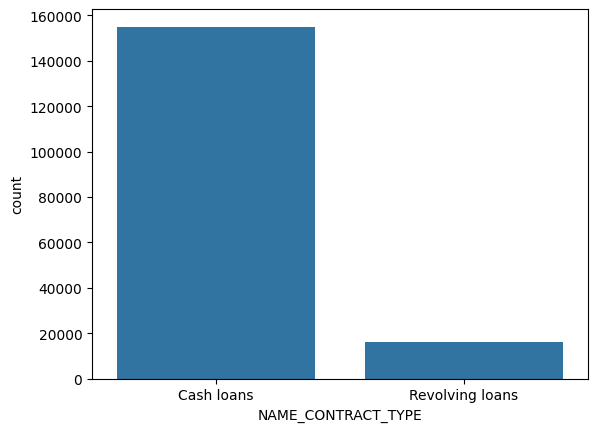

In [57]:
# The distribution of NAME_CONTRACT_TYPE
sns.countplot(data=train, x="NAME_CONTRACT_TYPE")
plt.show()

There are two variables in `NAME_CONTRACT_TYPE`, Cash loans and Revolving loans, but they are not evenly distributed. Also, since the machine learning model can only handle data of numeric type, it is necessary to convert the data from string type to numeric type.

**Findings**:<br>
* (May) need to think about methods to mitigate the skewedness of the target variable
* Need to convert the data from string type to numeric type

#### ORGANIZATION_TYPE column

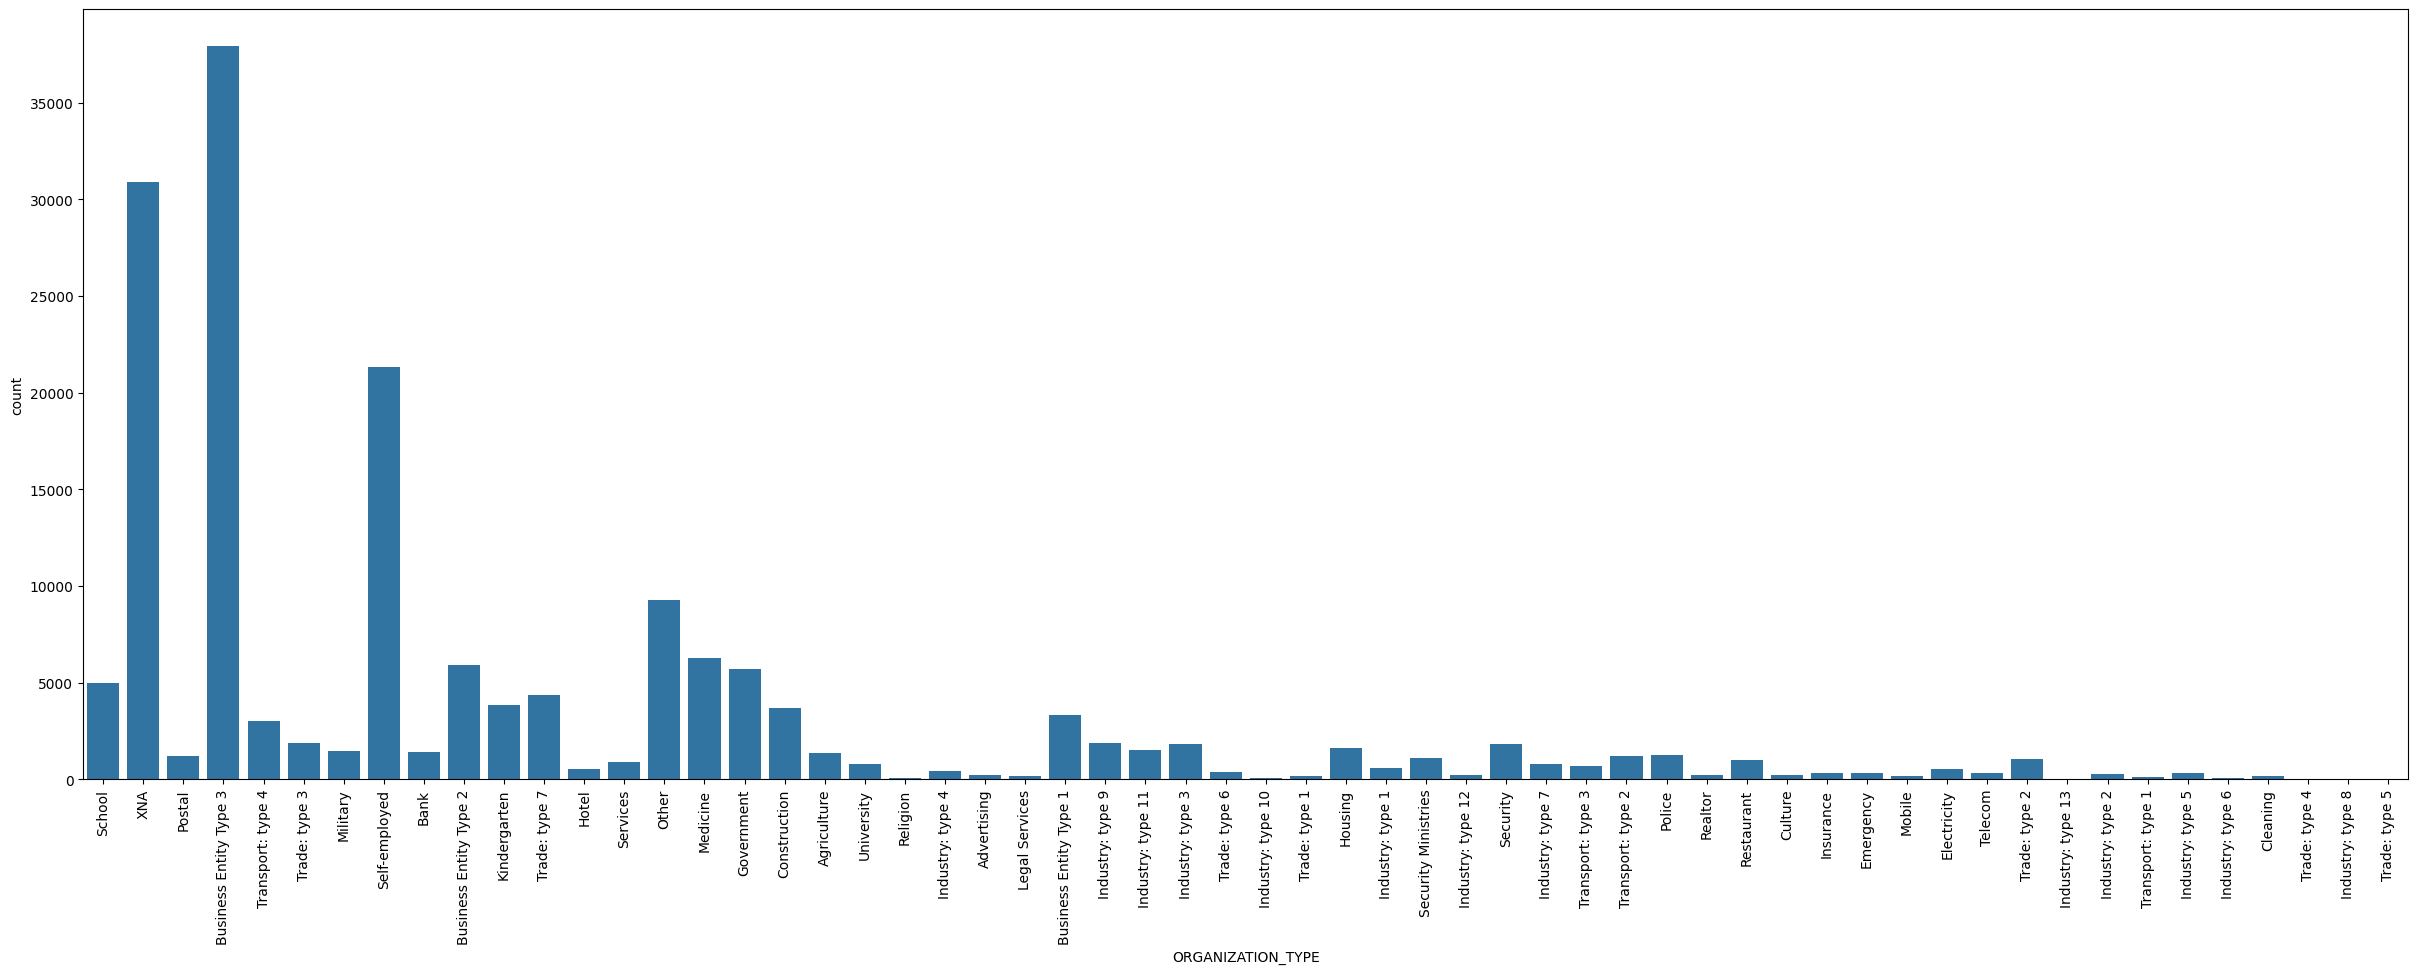

In [58]:
# The distribution of ORGANIZATION_TYPE
plt.figure(figsize=(30, 10))
sns.countplot(data=train, x="ORGANIZATION_TYPE")
plt.tick_params(axis="x", rotation=90)
plt.show()

There are many different `ORGANIZATION_TYPE`s, and you can also see that there is an ununiformity in the number of data. This is also a string type feature, so it needs to be converted to a numeric type. Also, the second variable from the left is "XNA", which we can infer from its name to be a missing value.


**Findings**:<br>
* Treat "XNA" as missing values
* Need to convert the data from string type to numeric type

#### EXT_SOURCE_2 column

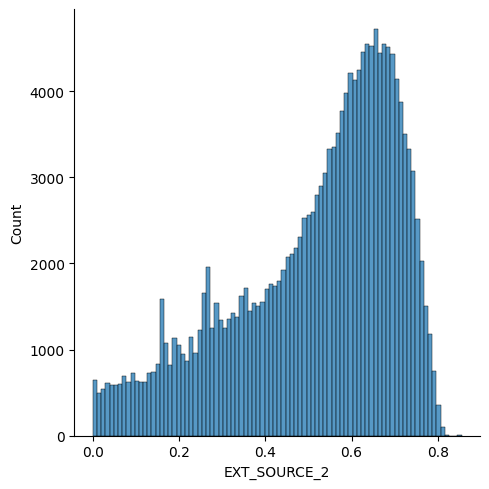

In [59]:
# The distribution of EXT_SOURCE_2
sns.displot(data=train, x="EXT_SOURCE_2")
plt.show()

We can see that EXT_SOURCE_2 is normalized between 0 and 1. It seems we can handle this feature as it is.

**Findings**:<br>
* No additional preprocessing is needed

#### AMT_INCOME_TOTAL column

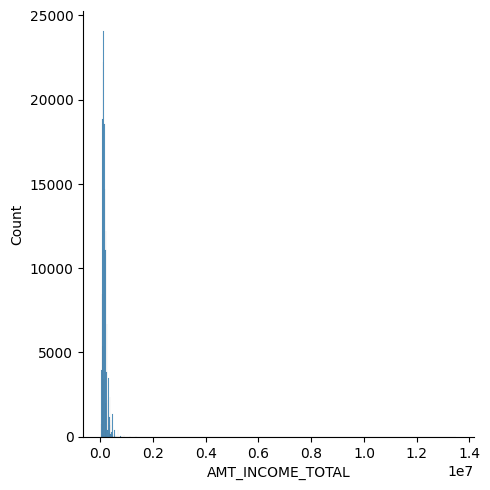

In [60]:
# The distribution of AMT_INCOME_TOTAL
sns.displot(data=train, x="AMT_INCOME_TOTAL")
plt.show()

The visualization of `AMT_INCOME_TOTAL` is hard to interpret. THis may be caused by the presence of a small number of outliers that take large values. To visualize data like this, a logarithmic transformation can be effective.

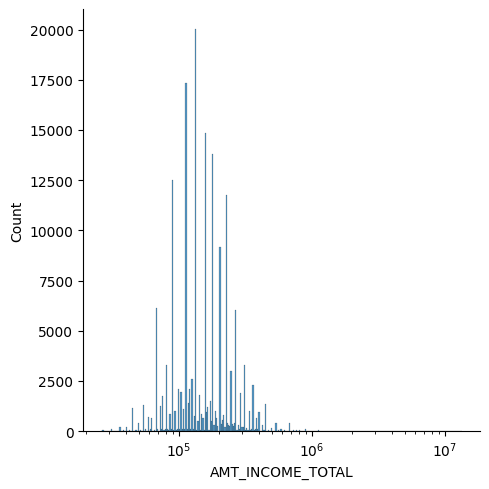

In [61]:
# The distribution of AMT_INCOME_TOTAL（Logarithmic transformation）
sns.displot(data=train, x="AMT_INCOME_TOTAL", log_scale=10)
plt.show()

We displayed the graph successfully by using logarithmic transformation.
The income is supposed to be a continuous value, but it looks like a discrete value. Let's have a look at the type of `AMT_INCOME_TOTAL` values.

In [62]:
# Check the type of AMT_INCOME_TOTAL values
len(train["AMT_INCOME_TOTAL"].unique())

1641

There are 171202 data in train, but `AMT_INCOME_TOTAL` consists of only 1641 different values. Let's check the top 10 values specifically.

In [63]:
# Top 10 values of AMT_INCOME_TOTAL
train["AMT_INCOME_TOTAL"].value_counts().head(10)

AMT_INCOME_TOTAL
135000.0    19969
112500.0    17320
157500.0    14772
180000.0    13791
90000.0     12481
225000.0    11573
202500.0     9128
67500.0      6130
270000.0     6006
81000.0      3295
Name: count, dtype: int64

It appears that `AMT_INCOME_TOTAL` is not an exact annual income, but rather data compiled from a rounded number.

**Findings**:<br>
* Should the outlier in the data be addressed?

#### OWN_CAR_AGE column

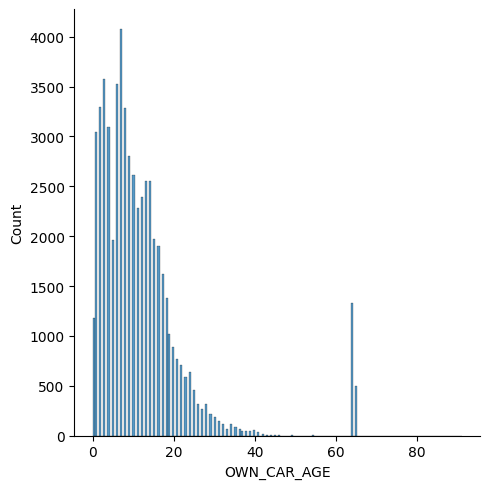

In [64]:
# The distribution of OWN_CAR_AGE
sns.displot(data=train, x="OWN_CAR_AGE")
plt.show()

`OWN_CAR_AGE` can be inferred to be in years from the scale of values. In addition, the distribution is natural from 0 to 40, but there is an unnatural distribution around 60 to 70. It is hard to imagine that the number of years a car has been purchased increases suddenly like this, so they are considered to be outliers.

**Findings**:<br>
* Treat numbers above 60 as outliers

Up to this point, we have visualized and analyzed each feature. I believe that you have realized that visualization requires some ingenuity and that visualization can deepen your understanding of data. I am sure that the visualization and analysis of the 25 features not covered here will lead to improved forecasting accuracy.

### **[Next Steps]**
> + Check for missing values for the features you have added in Section 2.2.
> + Visualize the features you have added. Is the feature categorical or continuous? What type of graph is most effective to understand it?
> + What do you notice about the features? What kind of preprocessing is needed?

## 4.Preprocessing and Feature Creation
Here, we will conduct the preprocessing and create new features based on what we have learned in the preceding visualization and analysis.

### NAME_CONTRACT_TYPE column
Convert `NAME_CONTRACT_TYPE` to a numeric type. In this case, “Cash loans” is converted to 0 and “Revolving loans” to 1. This method of simply replacing an integer is called **Label Encoding**.

In [65]:
# --- Section 3: Preprocessing Categoricals & Handling Missing Values ---
# Combine train and test to ensure consistent encoding across both splits
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder

train_X = train_feats.copy()
test_X  = test_feats.copy()

cat_cols = train_X.select_dtypes(include=['object']).columns.tolist()
print(f'Found {len(cat_cols)} categorical columns: {cat_cols}')

# Label encode categorical columns preserving NaNs
for col in cat_cols:
    le = LabelEncoder()
    combined = pd.concat([train_X[col], test_X[col]], axis=0).astype(str)
    le.fit(combined)
    train_X[col] = le.transform(train_X[col].astype(str))
    test_X[col]  = le.transform(test_X[col].astype(str))

print('Categorical encoding complete.')
print(f'train_X shape: {train_X.shape}, test_X shape: {test_X.shape}')


Found 8 categorical columns: ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE']
Categorical encoding complete.
train_X shape: (171202, 32), test_X shape: (61500, 32)


### ORGANIZATION_TYPE column
Convert `ORGANIZATION_TYPE` to a numeric type. This time, we will convert the variable to numeric in terms of the number of data in the variable. For example, if the number of data in “Police” is 1279 and the number of data in “Bank” is 1385, convert “Police” to 1279 and “Bank” to 1385. This method of replacing the number of data with the number of data is called **Count Encoding**.

In [66]:
# Categorical encoding already done above.
print("All categoricals encoded via LabelEncoder.")


All categoricals encoded via LabelEncoder.


### EXT_SOURCE_2 column
Fill missing values in `EXT_SOURCE_2`. There are various methods for completing missing values, but in this case, since the number of missing values is small, we simply use the average value to complete the missing values.

**IMPORANT**:
When you fill the missing values in the test data, you need to **fill with the average of the train data**.

In [67]:
# --- Section 4: Advanced Feature Engineering ---
# 1. Employment Anomaly
for df in [train_X, test_X]:
    df['DAYS_EMPLOYED_ANOM'] = (df['DAYS_EMPLOYED'] == 365243).astype(int)
    df['DAYS_EMPLOYED_CLEAN'] = df['DAYS_EMPLOYED'].replace(365243, np.nan)

    # 2. Financial & Credit Ratios (Home Credit benchmarks)
    df['PAYMENT_RATE'] = df['AMT_ANNUITY'] / (df['AMT_CREDIT'] + 1.0)
    df['CREDIT_INCOME_RATIO'] = df['AMT_CREDIT'] / (df['AMT_INCOME_TOTAL'] + 1.0)
    df['ANNUITY_INCOME_RATIO'] = df['AMT_ANNUITY'] / (df['AMT_INCOME_TOTAL'] + 1.0)
    df['CREDIT_GOODS_RATIO'] = df['AMT_CREDIT'] / (df['AMT_GOODS_PRICE'] + 1.0)
    df['GOODS_CREDIT_DIFF'] = df['AMT_GOODS_PRICE'] - df['AMT_CREDIT']
    df['INCOME_CREDIT_DIFF'] = df['AMT_INCOME_TOTAL'] - df['AMT_CREDIT']
    df['INCOME_PER_PERSON'] = df['AMT_INCOME_TOTAL'] / (df['CNT_FAM_MEMBERS'] + 1.0)
    df['CREDIT_PER_PERSON'] = df['AMT_CREDIT'] / (df['CNT_FAM_MEMBERS'] + 1.0)
    df['ANNUITY_PER_PERSON'] = df['AMT_ANNUITY'] / (df['CNT_FAM_MEMBERS'] + 1.0)

    # 3. Demographic & Age Ratios
    df['AGE_YEARS'] = -df['DAYS_BIRTH'] / 365.25
    df['EMPLOYED_YEARS'] = -df['DAYS_EMPLOYED_CLEAN'] / 365.25
    df['EMPLOYED_TO_BIRTH_RATIO'] = df['DAYS_EMPLOYED_CLEAN'] / (df['DAYS_BIRTH'] - 1.0)
    df['ID_TO_BIRTH_RATIO'] = df['DAYS_ID_PUBLISH'] / (df['DAYS_BIRTH'] - 1.0)
    df['REG_TO_BIRTH_RATIO'] = df['DAYS_REGISTRATION'] / (df['DAYS_BIRTH'] - 1.0)
    df['PHONE_TO_BIRTH_RATIO'] = df['DAYS_LAST_PHONE_CHANGE'] / (df['DAYS_BIRTH'] - 1.0)
    df['CAR_TO_BIRTH_RATIO'] = df['OWN_CAR_AGE'] / (df['AGE_YEARS'] + 1.0)
    df['CAR_TO_EMPLOYED_RATIO'] = df['OWN_CAR_AGE'] / (df['EMPLOYED_YEARS'] + 1.0)

    # 4. External Source Interactions (Primary signal carriers)
    ext_cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
    df['EXT_SOURCES_MEAN'] = df[ext_cols].mean(axis=1)
    df['EXT_SOURCES_STD']  = df[ext_cols].std(axis=1)
    df['EXT_SOURCES_MIN']  = df[ext_cols].min(axis=1)
    df['EXT_SOURCES_MAX']  = df[ext_cols].max(axis=1)
    df['EXT_SOURCES_PROD'] = df['EXT_SOURCE_1'].fillna(1) * df['EXT_SOURCE_2'].fillna(1) * df['EXT_SOURCE_3'].fillna(1)
    df['EXT_1_x_2'] = df['EXT_SOURCE_1'] * df['EXT_SOURCE_2']
    df['EXT_2_x_3'] = df['EXT_SOURCE_2'] * df['EXT_SOURCE_3']
    df['EXT_1_x_3'] = df['EXT_SOURCE_1'] * df['EXT_SOURCE_3']
    df['EXT_SOURCES_OVER_AGE'] = df['EXT_SOURCES_MEAN'] / (df['AGE_YEARS'] + 1.0)
    df['EXT_2_OVER_AGE'] = df['EXT_SOURCE_2'] / (df['AGE_YEARS'] + 1.0)
    df['EXT_3_OVER_AGE'] = df['EXT_SOURCE_3'] / (df['AGE_YEARS'] + 1.0)
    df['EXT_SOURCE_WEIGHTED'] = (
        df['EXT_SOURCE_1'].fillna(0.5) * 1.5 +
        df['EXT_SOURCE_2'].fillna(0.5) * 3.0 +
        df['EXT_SOURCE_3'].fillna(0.5) * 3.5
    )

    # 5. Bureau Inquiry Aggregations
    bureau_cols = [
        'AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_MON',
        'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR'
    ]
    df['BUREAU_TOTAL_REQ'] = df[bureau_cols].sum(axis=1)
    df['BUREAU_MON_TO_YEAR'] = df['AMT_REQ_CREDIT_BUREAU_MON'] / (df['AMT_REQ_CREDIT_BUREAU_YEAR'] + 1.0)

# 6. Group-by Mean Target Signals (Aggregated from train)
for grp in ['OCCUPATION_TYPE', 'ORGANIZATION_TYPE', 'NAME_EDUCATION_TYPE']:
    for col in ['EXT_SOURCE_2', 'AMT_CREDIT']:
        grp_mean = train_X.groupby(grp)[col].mean()
        train_X[f'{col}_BY_{grp}_MEAN'] = train_X[grp].map(grp_mean)
        test_X[f'{col}_BY_{grp}_MEAN']  = test_X[grp].map(grp_mean)
        train_X[f'{col}_BY_{grp}_RATIO'] = train_X[col] / (train_X[f'{col}_BY_{grp}_MEAN'] + 1e-5)
        test_X[f'{col}_BY_{grp}_RATIO']  = test_X[col] / (test_X[f'{col}_BY_{grp}_MEAN'] + 1e-5)

print(f'Feature engineering complete! Total features: {train_X.shape[1]}')


Feature engineering complete! Total features: 77


### OWN_CAR_AGE column
First, we will replace the unnatural outliers that are over 60 as `np.nan` (missing values).

In [68]:
for df in [train_X, test_X]:
    if "OWN_CAR_AGE" in df.columns:
        df.loc[df["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan
print("OWN_CAR_AGE clipped.")


OWN_CAR_AGE clipped.


Next, we consider the handling of missing values. The original `OWN_CAR_AGE` had 112992 missing values out of 171202 data. With such a large number of missing values, it is difficult and impractical to properly fill the missing values with some value. Therefore, we will group `OWN_CAR_AGE` by decade (e.g. Group 1: 0-9 years, Group 2: 10-19 years, etc.), then apply **One Hot Encoding**.

In [69]:
print("OWN_CAR_AGE left as-is for LightGBM.")


OWN_CAR_AGE left as-is for LightGBM.


In [70]:
print("Final feature count:", train_X.shape[1])
print(train_X.dtypes.value_counts())


Final feature count: 77
float64    60
int64      17
Name: count, dtype: int64


### **[Next Steps]**
> + Apply preprocessing to the features you added. Is it correctly preprocessed?
> + Explore other preprocessing methods to apply to the features.
> + If you have errors, try reloading the dataset by going back to [Section 2.1](#scrollTo=2TTHzi1c3a5E&line=5&uniqifier=1).

## 5.Building the Machine Learning Model
Now, we are ready to start building the machine learning model.

### 5.1 Import Additional Libraries
First, we import the necessary libraries for training and evaluation.

- `train_test_split`: Split data into training and evaluation data.
- `StandardScaler`: Standardize the data.
- `roc_auc_score`: Calculate ROC-AUC, the evaluation metric for this competition.

In [71]:
# --- Section 5: Model Setup ---
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import numpy as np

try:
    from catboost import CatBoostClassifier
    HAS_CATBOOST = True
    print('CatBoost available for ensembling.')
except ImportError:
    HAS_CATBOOST = False

print('LightGBM version:', lgb.__version__)


CatBoost available for ensembling.
LightGBM version: 4.7.0


### 5.2 Preparing the Data
Split the data into explanatory and target variables. The target variable for this dataset is `TARGET` column and the rest are explanatory variables.

In [72]:
train_X, test_X = train_X.align(test_X, join="left", axis=1)

X       = train_X.values
y       = target
X_test  = test_X.values
feature_names = list(train_X.columns)

print("X shape       :", X.shape)
print("X_test shape  :", X_test.shape)
print("y distribution:", np.bincount(y))


X shape       : (171202, 77)
X_test shape  : (61500, 77)
y distribution: [157381  13821]


Standardize the data. Standardization is the operation of transforming the values so that the mean is 0 and the variance is 1. Some models, such as logistic regression and neural networks, do not learn well without scaling the values in this way.

In [73]:
# LightGBM does NOT require feature scaling.
print("No scaling needed for LightGBM.")


No scaling needed for LightGBM.


### 5.3 Training the Model
We first split the training data into training data and validation data. This method of keeping a portion of the training data for evaluation and not using it for training is called the **holdout method**. This is one method to approximate the model's predictive ability on unknown data (**generalization** performance).

Here, we will use 70% of the data as training data and 30% as validation data

In [74]:
N_FOLDS = 5
SEED    = 42
skf     = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

oof_lgb = np.zeros(len(X))
test_lgb = np.zeros(len(X_test))

oof_cat = np.zeros(len(X))
test_cat = np.zeros(len(X_test))

print(f'Configured {N_FOLDS}-Fold Stratified CV ensemble...')


Configured 5-Fold Stratified CV ensemble...


Now, let's create models with logistic regression and random forest.

In [75]:
# --- Models: leakage-safe target encoding + 5-fold boosting ensemble ---
from sklearn.model_selection import StratifiedKFold

try:
    import xgboost as xgb
    HAS_XGBOOST = True
    print('XGBoost available for ensembling.')
except ImportError:
    HAS_XGBOOST = False
    print('XGBoost not installed; using the available models.')

N_FOLDS = 5
SEED = 42
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

te_cols = [
    col for col in [
        'ORGANIZATION_TYPE', 'OCCUPATION_TYPE',
        'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE'
    ]
    if col in train.columns
]
te_train_categories = train[te_cols].fillna('__MISSING__').astype(str).reset_index(drop=True)
te_test_categories = test[te_cols].fillna('__MISSING__').astype(str).reset_index(drop=True)


def smoothed_target_encoding(reference_categories, reference_target, apply_categories, smoothing=20.0):
    prior = float(np.mean(reference_target))
    stats = pd.DataFrame({
        'category': reference_categories.to_numpy(),
        'target': reference_target
    }).groupby('category')['target'].agg(['sum', 'count'])
    encoded = (stats['sum'] + smoothing * prior) / (stats['count'] + smoothing)
    return apply_categories.map(encoded).fillna(prior).to_numpy(dtype=float)


lgb_params = {
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    'n_estimators': 2000,
    'learning_rate': 0.02,
    'num_leaves': 31,
    'max_depth': -1,
    'min_child_samples': 60,
    'subsample': 0.8,
    'subsample_freq': 1,
    'colsample_bytree': 0.6,
    'reg_alpha': 0.1,
    'reg_lambda': 10.0,
    'random_state': SEED,
    'n_jobs': -1,
    'verbose': -1,
}

cat_params = {
    'iterations': 1200,
    'learning_rate': 0.03,
    'depth': 6,
    'eval_metric': 'AUC',
    'l2_leaf_reg': 10.0,
    'random_seed': SEED,
    'verbose': 0,
    'thread_count': -1,
}

if HAS_XGBOOST:
    xgb_params = {
        'n_estimators': 1400,
        'learning_rate': 0.03,
        'max_depth': 4,
        'min_child_weight': 50,
        'subsample': 0.8,
        'colsample_bytree': 0.6,
        'reg_lambda': 10.0,
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'tree_method': 'hist',
        'random_state': SEED,
        'n_jobs': -1,
    }

oof_lgb = np.zeros(len(X))
test_lgb = np.zeros(len(X_test))
oof_cat = np.zeros(len(X))
test_cat = np.zeros(len(X_test))
oof_xgb = np.zeros(len(X))
test_xgb = np.zeros(len(X_test))
fold_indices = list(skf.split(X, y))

print(f'Training {N_FOLDS}-fold ensemble with {len(te_cols)} target-encoded columns...')
for fold, (tr_idx, val_idx) in enumerate(fold_indices, 1):
    X_tr_base, X_val_base = X[tr_idx], X[val_idx]
    y_tr, y_val = y[tr_idx], y[val_idx]
    categories_tr = te_train_categories.iloc[tr_idx].reset_index(drop=True)
    categories_val = te_train_categories.iloc[val_idx].reset_index(drop=True)

    # Cross-fit encodings for model-training rows; outer-fold labels never enter validation encodings.
    inner_skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + fold)
    te_tr = np.zeros((len(tr_idx), len(te_cols)), dtype=float)
    for inner_tr_idx, inner_val_idx in inner_skf.split(X_tr_base, y_tr):
        for col_idx, col in enumerate(te_cols):
            te_tr[inner_val_idx, col_idx] = smoothed_target_encoding(
                categories_tr[col].iloc[inner_tr_idx], y_tr[inner_tr_idx],
                categories_tr[col].iloc[inner_val_idx]
            )

    te_val = np.column_stack([
        smoothed_target_encoding(categories_tr[col], y_tr, categories_val[col])
        for col in te_cols
    ]) if te_cols else np.empty((len(val_idx), 0))
    te_test = np.column_stack([
        smoothed_target_encoding(categories_tr[col], y_tr, te_test_categories[col])
        for col in te_cols
    ]) if te_cols else np.empty((len(X_test), 0))

    X_tr_model = np.column_stack([X_tr_base, te_tr])
    X_val_model = np.column_stack([X_val_base, te_val])
    X_test_model = np.column_stack([X_test, te_test])

    model_lgb = lgb.LGBMClassifier(**lgb_params)
    model_lgb.fit(
        X_tr_model, y_tr,
        eval_set=[(X_val_model, y_val)],
        callbacks=[
            lgb.early_stopping(stopping_rounds=80, verbose=False),
            lgb.log_evaluation(period=0)
        ]
    )
    pred_lgb = model_lgb.predict_proba(X_val_model)[:, 1]
    oof_lgb[val_idx] = pred_lgb
    test_lgb += model_lgb.predict_proba(X_test_model)[:, 1] / N_FOLDS
    print(f'  LGB fold {fold} AUC: {roc_auc_score(y_val, pred_lgb):.5f} | Best iteration: {model_lgb.best_iteration_}')

    if HAS_CATBOOST:
        model_cat = CatBoostClassifier(**cat_params)
        model_cat.fit(X_tr_model, y_tr, eval_set=(X_val_model, y_val), early_stopping_rounds=60)
        pred_cat = model_cat.predict_proba(X_val_model)[:, 1]
        oof_cat[val_idx] = pred_cat
        test_cat += model_cat.predict_proba(X_test_model)[:, 1] / N_FOLDS
        print(f'  CAT fold {fold} AUC: {roc_auc_score(y_val, pred_cat):.5f}')

    if HAS_XGBOOST:
        try:
            model_xgb = xgb.XGBClassifier(**xgb_params, early_stopping_rounds=80)
            model_xgb.fit(X_tr_model, y_tr, eval_set=[(X_val_model, y_val)], verbose=False)
        except TypeError:
            model_xgb = xgb.XGBClassifier(**xgb_params)
            try:
                model_xgb.fit(
                    X_tr_model, y_tr, eval_set=[(X_val_model, y_val)],
                    early_stopping_rounds=80, verbose=False
                )
            except TypeError:
                model_xgb.fit(X_tr_model, y_tr, eval_set=[(X_val_model, y_val)], verbose=False)
        pred_xgb = model_xgb.predict_proba(X_val_model)[:, 1]
        oof_xgb[val_idx] = pred_xgb
        test_xgb += model_xgb.predict_proba(X_test_model)[:, 1] / N_FOLDS
        print(f'  XGB fold {fold} AUC: {roc_auc_score(y_val, pred_xgb):.5f}')

weights = {'lgb': 0.45}
if HAS_CATBOOST:
    weights['cat'] = 0.35
if HAS_XGBOOST:
    weights['xgb'] = 0.20
weight_total = sum(weights.values())
weights = {name: weight / weight_total for name, weight in weights.items()}

oof_preds = weights['lgb'] * oof_lgb
test_preds = weights['lgb'] * test_lgb
if HAS_CATBOOST:
    oof_preds += weights['cat'] * oof_cat
    test_preds += weights['cat'] * test_cat
if HAS_XGBOOST:
    oof_preds += weights['xgb'] * oof_xgb
    test_preds += weights['xgb'] * test_xgb

oof_score = roc_auc_score(y, oof_preds)
fold_scores = [roc_auc_score(y[val_idx], oof_preds[val_idx]) for _, val_idx in fold_indices]
print('\nBlend weights:', weights)
print(f'FINAL ENSEMBLE OOF AUC: {oof_score:.5f}')
print(f'Mean fold AUC: {np.mean(fold_scores):.5f}')

XGBoost available for ensembling.
Training 5-fold ensemble with 4 target-encoded columns...
  LGB fold 1 AUC: 0.75749 | Best iteration: 840
  CAT fold 1 AUC: 0.75666
  XGB fold 1 AUC: 0.75817
  LGB fold 2 AUC: 0.76209 | Best iteration: 753
  CAT fold 2 AUC: 0.76004
  XGB fold 2 AUC: 0.76305
  LGB fold 3 AUC: 0.76702 | Best iteration: 777
  CAT fold 3 AUC: 0.76368
  XGB fold 3 AUC: 0.76627
  LGB fold 4 AUC: 0.75637 | Best iteration: 667
  CAT fold 4 AUC: 0.75499
  XGB fold 4 AUC: 0.75744
  LGB fold 5 AUC: 0.76156 | Best iteration: 690
  CAT fold 5 AUC: 0.76071
  XGB fold 5 AUC: 0.76162

Blend weights: {'lgb': 0.45, 'cat': 0.35, 'xgb': 0.2}
FINAL ENSEMBLE OOF AUC: 0.76162
Mean fold AUC: 0.76167


In [76]:
# --- Native-categorical CatBoost experiment and OOF blend selection ---
if HAS_CATBOOST:
    cat_train_frame = train_X.copy().reset_index(drop=True)
    cat_test_frame = test_X.copy().reset_index(drop=True)
    for categorical_col in cat_cols:
        cat_train_frame[categorical_col] = train_feats[categorical_col].fillna('__MISSING__').astype(str).to_numpy()
        cat_test_frame[categorical_col] = test_feats[categorical_col].fillna('__MISSING__').astype(str).to_numpy()

    native_cat_oof = np.zeros(len(y))
    native_cat_test = np.zeros(len(X_test))
    native_cat_models = []
    for fold, (tr_idx, val_idx) in enumerate(fold_indices, 1):
        model_native_cat = CatBoostClassifier(**cat_params)
        model_native_cat.fit(
            cat_train_frame.iloc[tr_idx], y[tr_idx],
            cat_features=cat_cols,
            eval_set=(cat_train_frame.iloc[val_idx], y[val_idx]),
            early_stopping_rounds=60
        )
        native_cat_oof[val_idx] = model_native_cat.predict_proba(cat_train_frame.iloc[val_idx])[:, 1]
        native_cat_test += model_native_cat.predict_proba(cat_test_frame)[:, 1] / N_FOLDS
        native_cat_models.append(model_native_cat)
        print(f'  Native CAT fold {fold} AUC: {roc_auc_score(y[val_idx], native_cat_oof[val_idx]):.5f}')

    blend_components = [
        ('lgb', oof_lgb, test_lgb),
        ('native_cat', native_cat_oof, native_cat_test)
    ]
    if HAS_XGBOOST:
        blend_components.append(('xgb', oof_xgb, test_xgb))

    weight_candidates = []
    units = 10
    for integer_weights in __import__('itertools').product(range(units + 1), repeat=len(blend_components)):
        if sum(integer_weights) == units:
            weight_candidates.append(np.asarray(integer_weights, dtype=float) / units)

    def choose_blend_weights(oof_matrix, labels):
        return max(
            weight_candidates,
            key=lambda weights: roc_auc_score(labels, oof_matrix @ weights)
        )

    oof_matrix = np.column_stack([component[1] for component in blend_components])
    test_matrix = np.column_stack([component[2] for component in blend_components])
    meta_oof = np.zeros(len(y))
    for _, meta_val_idx in fold_indices:
        meta_train_mask = np.ones(len(y), dtype=bool)
        meta_train_mask[meta_val_idx] = False
        selected_weights = choose_blend_weights(oof_matrix[meta_train_mask], y[meta_train_mask])
        meta_oof[meta_val_idx] = oof_matrix[meta_val_idx] @ selected_weights

    final_weights = choose_blend_weights(oof_matrix, y)
    oof_preds = meta_oof
    test_preds = test_matrix @ final_weights
    oof_score = roc_auc_score(y, oof_preds)
    fold_scores = [roc_auc_score(y[val_idx], oof_preds[val_idx]) for _, val_idx in fold_indices]
    print('Blend components:', [component[0] for component in blend_components])
    print('Full-OOF fitted blend weights:', dict(zip([component[0] for component in blend_components], final_weights)))
    print(f'Cross-fitted blend OOF AUC: {oof_score:.5f}')
    print(f'Mean cross-fitted fold AUC: {np.mean(fold_scores):.5f}')
else:
    print('CatBoost unavailable; keeping the existing ensemble predictions.')

  Native CAT fold 1 AUC: 0.75679
  Native CAT fold 2 AUC: 0.75953
  Native CAT fold 3 AUC: 0.76360
  Native CAT fold 4 AUC: 0.75640
  Native CAT fold 5 AUC: 0.75963
Blend components: ['lgb', 'native_cat', 'xgb']
Full-OOF fitted blend weights: {'lgb': np.float64(0.3), 'native_cat': np.float64(0.2), 'xgb': np.float64(0.5)}
Cross-fitted blend OOF AUC: 0.76182
Mean cross-fitted fold AUC: 0.76188


In [83]:
# --- Check whether the supplied application ID has stable fold signal ---
id_values = train_full['SK_ID_CURR'].to_numpy()
id_fold_auc = [roc_auc_score(y[val_idx], id_values[val_idx]) for _, val_idx in fold_indices]
print('SK_ID_CURR validation AUC by fold:', [round(score, 5) for score in id_fold_auc])
print(f'Mean ID-only validation AUC: {np.mean(id_fold_auc):.5f}')

SK_ID_CURR validation AUC by fold: [np.float64(0.49899), np.float64(0.50404), np.float64(0.50354), np.float64(0.50791), np.float64(0.49989)]
Mean ID-only validation AUC: 0.50288


In [84]:
# --- Native-categorical LightGBM experiment ---
native_lgb_train = train_X.copy().reset_index(drop=True)
native_lgb_test = test_X.copy().reset_index(drop=True)
for categorical_col in cat_cols:
    train_categories = train_feats[categorical_col].fillna('__MISSING__').astype(str).reset_index(drop=True)
    test_categories = test_feats[categorical_col].fillna('__MISSING__').astype(str).reset_index(drop=True)
    category_levels = pd.Index(pd.concat([train_categories, test_categories], ignore_index=True).unique())
    native_lgb_train[categorical_col] = pd.Categorical(train_categories, categories=category_levels)
    native_lgb_test[categorical_col] = pd.Categorical(test_categories, categories=category_levels)

native_lgb_oof = np.zeros(len(y))
native_lgb_test_pred = np.zeros(len(X_test))
for fold, (tr_idx, val_idx) in enumerate(fold_indices, 1):
    categories_tr = te_train_categories.iloc[tr_idx].reset_index(drop=True)
    categories_val = te_train_categories.iloc[val_idx].reset_index(drop=True)
    y_tr, y_val = y[tr_idx], y[val_idx]

    inner_skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + fold)
    te_tr = np.zeros((len(tr_idx), len(te_cols)), dtype=float)
    for inner_tr_idx, inner_val_idx in inner_skf.split(np.zeros(len(tr_idx)), y_tr):
        for col_idx, col in enumerate(te_cols):
            te_tr[inner_val_idx, col_idx] = smoothed_target_encoding(
                categories_tr[col].iloc[inner_tr_idx], y_tr[inner_tr_idx],
                categories_tr[col].iloc[inner_val_idx]
            )

    te_val = np.column_stack([
        smoothed_target_encoding(categories_tr[col], y_tr, categories_val[col])
        for col in te_cols
    ])
    te_test = np.column_stack([
        smoothed_target_encoding(categories_tr[col], y_tr, te_test_categories[col])
        for col in te_cols
    ])

    X_tr_native = native_lgb_train.iloc[tr_idx].copy()
    X_val_native = native_lgb_train.iloc[val_idx].copy()
    X_test_native = native_lgb_test.copy()
    for col_idx, col in enumerate(te_cols):
        encoded_col = f'{col}_TARGET_ENCODED'
        X_tr_native[encoded_col] = te_tr[:, col_idx]
        X_val_native[encoded_col] = te_val[:, col_idx]
        X_test_native[encoded_col] = te_test[:, col_idx]

    model_native_lgb = lgb.LGBMClassifier(**lgb_params)
    model_native_lgb.fit(
        X_tr_native, y_tr,
        eval_set=[(X_val_native, y_val)],
        callbacks=[
            lgb.early_stopping(stopping_rounds=80, verbose=False),
            lgb.log_evaluation(period=0)
        ]
    )
    native_lgb_oof[val_idx] = model_native_lgb.predict_proba(X_val_native)[:, 1]
    native_lgb_test_pred += model_native_lgb.predict_proba(X_test_native)[:, 1] / N_FOLDS
    print(f'  Native LGB fold {fold} AUC: {roc_auc_score(y_val, native_lgb_oof[val_idx]):.5f}')

native_lgb_auc = roc_auc_score(y, native_lgb_oof)
current_oof_auc = roc_auc_score(y, oof_preds)
combined_native_oof = 0.5 * oof_preds + 0.5 * native_lgb_oof
combined_native_auc = roc_auc_score(y, combined_native_oof)
print(f'Native-categorical LightGBM OOF AUC: {native_lgb_auc:.5f}')
print(f'50/50 current + native LightGBM OOF AUC: {combined_native_auc:.5f}')

if combined_native_auc > current_oof_auc:
    oof_preds = combined_native_oof
    test_preds = 0.5 * test_preds + 0.5 * native_lgb_test_pred
    oof_score = combined_native_auc
    fold_scores = [roc_auc_score(y[val_idx], oof_preds[val_idx]) for _, val_idx in fold_indices]
    print('Using the native-categorical LightGBM blend for submission.')
else:
    print('Keeping the current blend; native-categorical LightGBM did not improve OOF AUC.')

  Native LGB fold 1 AUC: 0.75624
  Native LGB fold 2 AUC: 0.76008
  Native LGB fold 3 AUC: 0.76421
  Native LGB fold 4 AUC: 0.75519
  Native LGB fold 5 AUC: 0.76027
Native-categorical LightGBM OOF AUC: 0.75913
50/50 current + native LightGBM OOF AUC: 0.76117
Keeping the current blend; native-categorical LightGBM did not improve OOF AUC.


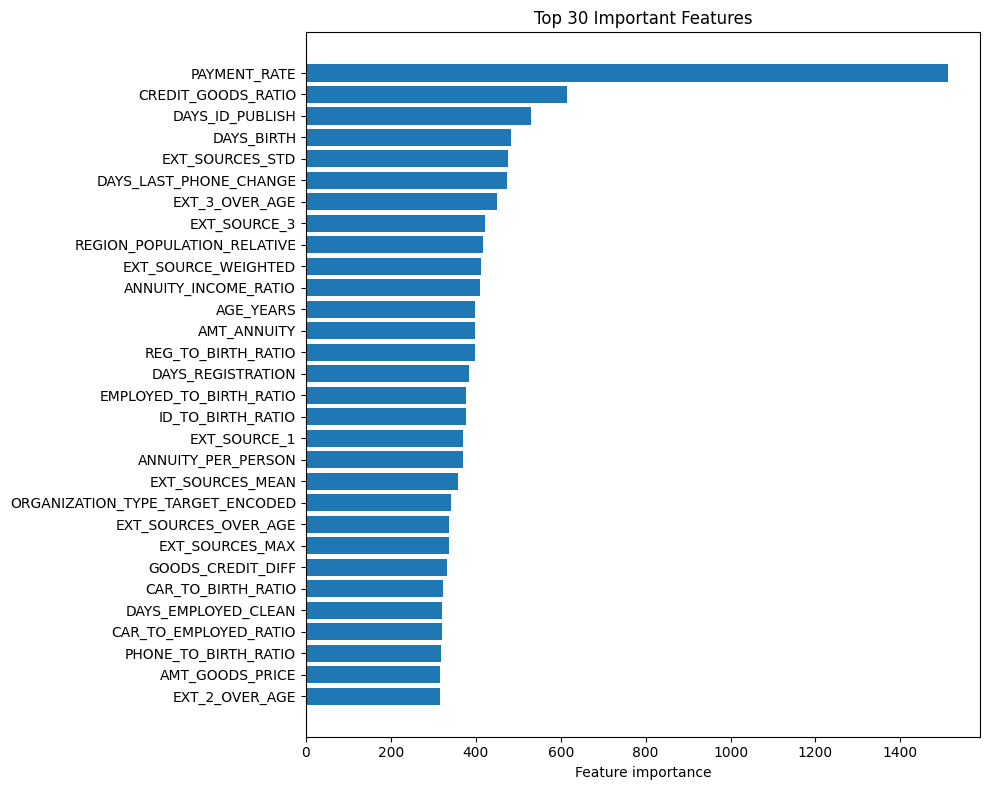

,feature,importance
34,PAYMENT_RATE,1512
37,CREDIT_GOODS_RATIO,615
15,DAYS_ID_PUBLISH,529
12,DAYS_BIRTH,484
52,EXT_SOURCES_STD,477
27,DAYS_LAST_PHONE_CHANGE,473
61,EXT_3_OVER_AGE,449
26,EXT_SOURCE_3,421
11,REGION_POPULATION_RELATIVE,418
62,EXT_SOURCE_WEIGHTED,412


In [77]:
import matplotlib.pyplot as plt

model_feature_names = feature_names + [f'{col}_TARGET_ENCODED' for col in te_cols]
fi = pd.DataFrame({
    'feature': model_feature_names,
    'importance': model_lgb.feature_importances_
}).sort_values('importance', ascending=False)

plt.figure(figsize=(10, 8))
plt.barh(fi['feature'].head(30)[::-1], fi['importance'].head(30)[::-1])
plt.xlabel('Feature importance')
plt.title('Top 30 Important Features')
plt.tight_layout()
plt.show()

fi.head(20)

We find that random forest results with higher validation score.

### 5.4 (Optional) Ensemble Learning
Now that we have created two models, we can try combining these two models for better predictive ability (**ensemble learning**). There are various methods for ensemble learning, but here we will simply take the average of the two models.

In [78]:
print("OOF AUC     : {:.5f}".format(oof_score))
for i, s in enumerate(fold_scores, 1):
    print("  Fold {}: {:.5f}".format(i, s))
print("Mean CV AUC : {:.5f}".format(np.mean(fold_scores)))


OOF AUC     : 0.76182
  Fold 1: 0.75888
  Fold 2: 0.76323
  Fold 3: 0.76715
  Fold 4: 0.75789
  Fold 5: 0.76224
Mean CV AUC : 0.76188


We find that in this case, ensemble leaning does not contribute to improved score. So, **we will use the random forest model as the final model to make predictions on the test data**.

### **[Next Steps]**
> + Is holdout method the best method to evaluate your model?
> + Is the model's hyperparameters optimized? What hyperparameters needs tuning?
> + Explore other models to use to make predictions.
> + Explore other ensembling methods to further improve the model's performance.
> + If you have errors, try reloading the dataset by going back to [Section 2.1](#scrollTo=2TTHzi1c3a5E&line=5&uniqifier=1).

## 6.Creating Prediction Results
Finally, let's make a prediction for the test data, and prepare a CSV file to submit.

### 6.1 Predicting on the test data
We found in Sections 5.3 and 5.4 that the best model was random forest model. Therefore, we will use this model to make the final prediction.

If you made any changes and found a better model, you will need to change the code below accordingly.

```python
# If logistic regression model was better
pred = lr.predict_proba(X_test_std)[:, 1]
```

In [79]:
pred = test_preds
print("Test prediction stats: min={:.4f}, max={:.4f}, mean={:.4f}".format(pred.min(), pred.max(), pred.mean()))


Test prediction stats: min=0.0025, max=0.7663, mean=0.0888


### 6.2 Saving the prediction as CSV file [DO NOT CHANGE]
**WARNING**: DO **NOT** CHANGE THE CODES BELOW!!!

In [80]:
# Put the prediction into the format of submission
sample_sub['TARGET'] = pred
sample_sub

,SK_ID_CURR,TARGET
0,171202,0.035855
1,171203,0.188259
2,171204,0.147123
3,171205,0.109676
4,171206,0.194273
...,...,...
61495,232697,0.202928
61496,232698,0.033395
61497,232699,0.054203
61498,232700,0.188092


In [81]:
# Create the "output" directory if it doesn't exist
output_dir = current_dir / "output"
os.makedirs(output_dir, exist_ok=True)

# Specify the new output file path
output_file = output_dir / "submission.csv"

# Save the CSV file to the "output" directory
sample_sub.to_csv(output_file, index=False)

That's all for the tutorial of Home Credit Default Risk competition! Submit your CSV file to Omnicampus to see the result.

Only 5 out of 30 features are covered in this notebook, so there are a lot of room for improvement. Check out **[Next Steps]** in each section to see what you can do to improve your score.

### 6.3 Saving this notebook as a ZIP file [REQUIREMENT IF AIMING FOR HONORS/OUTSTANDING STUDENTS]
This section compresses the notebook file (`tutorial.ipynb`) into a ZIP file and saves it to your working directory.
Make sure to save the notebook (Ctrl+S or Cmd+S) before running this cell to include the latest changes.

If you are aiming to become **Honors or Outstanding Student**, you need to submit the ZIP file as well on Omnicampus.

In [82]:
import zipfile

# Define the file names
notebook_filename = "tutorial.ipynb" # Enter the name of this notebook
zip_filename = "tutorial.zip"

# Define the full paths using current_dir
notebook_path = current_dir / notebook_filename
zip_output_path = current_dir / zip_filename

# Check if the notebook file exists and create the ZIP file
if notebook_path.exists():
    with zipfile.ZipFile(zip_output_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
        # Add the notebook to the ZIP file (arcname avoids including the full folder structure)
        zipf.write(notebook_path, arcname=notebook_filename)
    print(f"Successfully created: {zip_output_path}")
else:
    print(f"Error: Could not find '{notebook_filename}' in {current_dir}.")
    print("Please check if the notebook name and the current directory are correct.")

Successfully created: c:\Users\Hareen Liyanage\Desktop\GCI_World_Competition\tutorial.zip
